# 神经网络
## 从感知机到神经网络
## 激活函数
### sigmoid 函数
### 阶跃函数的实现

In [1]:
import numpy as np


def step_function2(x):
    if x > 0:
        return 1
    else:
        return 0


def step_function(x):
    y = x > 0
    return y.astype(np.int64)

### 阶跃函数的图形
下面我们就用图来表示上面定义的阶跃函数，为此需要使用 matplotlib 库。

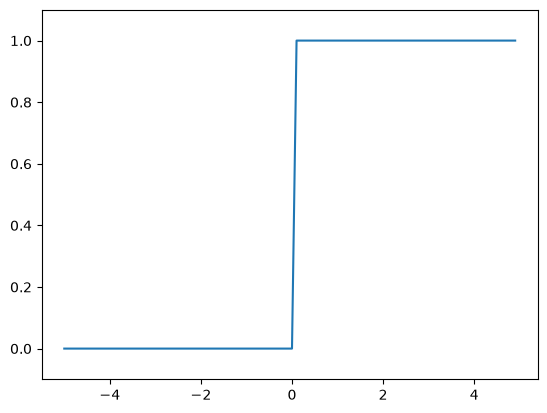

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def step_function(x):
    return np.array(x > 0, dtype=np.int64)  

x = np.arange(-5.0, 5.0, 0.1)  # 包含 -5.0, -4.9, -4.8, ..., 4.8, 4.9，不含 5.0
y = step_function(x)
plt.plot(x, y)
plt.ylim(-0.1, 1.1) # # 指定 y 轴的范围
plt.show()

### sigmoid 函数的实现
我们来实现 `sigmoid` 函数：

In [ ]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))



In [4]:
sigmoid(-1.0), sigmoid(1.0), sigmoid(2.0)

(np.float64(0.2689414213699951),
 np.float64(0.7310585786300049),
 np.float64(0.8807970779778823))

根据 NumPy 的广播功能，如果在标量和 NumPy 数组
之间进行运算，则标量会和 NumPy 数组的各个元素进行运算。

In [6]:
sigmoid(np.array([-1.0, 1.0, 2.0]))

array([0.26894142, 0.73105858, 0.88079708])

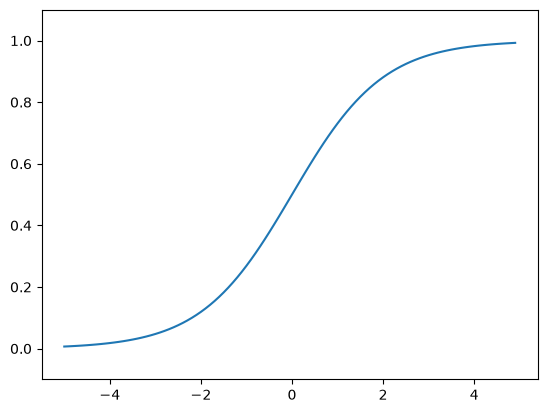

In [12]:
x = np.arange(-5.0, 5.0, 0.1)
y = sigmoid(x)
plt.plot(x, y)
plt.ylim(-0.1, 1.1)
plt.show()

### sigmoid 函数和阶跃函数的比较
**不同点**

1. “平滑性”的不同。`sigmoid` 函数是一条平滑的曲线，输出随着输入发生连续性的变化。而阶跃函数以 0 为界，输出发生急剧性的变化。`sigmoid` 函数的平滑性对神经网络的学习具有重要意义。
2. 相对于阶跃函数只能返回 0 或 1，sigmoid 函数可以返
回 `0.731...`、`0.880... ` 等实数（这一点和刚才的平滑性有关）。也就是说，感
知机中神经元之间流动的是 `0` 或 `1` 的二元信号，而神经网络中流动的是连续
的实数值信号。

**共同点**

1. 两者的结构均是“输入小时，输出接近 0（为 0）；
随着输入增大，输出向 1 靠近（变成 1）”。也就是说，当输入信号为重要信息时，
阶跃函数和 `sigmoid` 函数都会输出较大的值；当输入信号为不重要的信息时，
两者都输出较小的值。还有一个共同点是，不管输入信号有多小，或者有多
大，输出信号的值都在 0 到 1 之间。
2. 两者均为非线性函数。`sigmoid` 函数是一条曲线，阶跃函数是一条像阶梯一样的折线，两者都属于
非线性的函数。

### 非线性函数
### ReLU 函数
`ReLU` 函数在输入大于 0 时，直接输出该值；在输入小于等于 0 时，输出 0 。

In [13]:

def relu(x):
    return np.maximum(0, x)

## 多维数组的运算
掌握 NumPy 多维数组的运算，就可以高效地实现神经网络。
### 多维数组

In [17]:
import numpy as np
A = np.array([1, 2, 3, 4])
A, A.shape, A.shape[0], A.ndim, A.dtype

(array([1, 2, 3, 4]), (4,), 4, 1, dtype('int64'))

In [18]:
B = np.array([[1, 2], [3, 4], [5, 6]])
B, B.shape, B.shape[0], B.ndim, B.dtype

(array([[1, 2],
        [3, 4],
        [5, 6]]),
 (3, 2),
 3,
 2,
 dtype('int64'))

In [19]:
np.ndim(A), np.ndim(B)

(1, 2)

### 矩阵乘法
我们来介绍矩阵（二维数组）的乘积。比如 2 × 2 的矩阵，其乘积可以像下图这样进行计算（按图中顺序进行计算是规定好了的）。


<img src="imgs/2026-11-04_11-08-57.png" style="display: block; margin-left: auto; margin-right: auto;">

In [ ]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

np.dot(A, B)  # 矩阵乘法


array([[19, 22],
       [43, 50]])

这里介绍的是计算 2 × 2 形状的矩阵的乘积的例子，其他形状的矩阵的
乘积也可以用相同的方法来计算。比如，2 × 3 的矩阵和 3 × 2 的矩阵的乘积
可按如下形式用 Python 来实现。

In [24]:
A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[1, 2], [3, 4], [5, 6]])
A, B

(array([[1, 2, 3],
        [4, 5, 6]]),
 array([[1, 2],
        [3, 4],
        [5, 6]]))

In [25]:
np.dot(A, B)  # 矩阵乘法

array([[22, 28],
       [49, 64]])

In [27]:
import numpy as np

A = np.random.rand(2, 3)   # 2行3列
B = np.random.rand(3, 4)   # 3行4列

C = np.dot(A, B)
print(C.shape)             # (2, 4)
A,B

(2, 4)


(array([[0.9433173 , 0.3324778 , 0.01913767],
        [0.6062149 , 0.96639528, 0.14677204]]),
 array([[0.73200995, 0.47853149, 0.05938555, 0.76253502],
        [0.43297881, 0.24430892, 0.35370013, 0.76844405],
        [0.95134532, 0.3386708 , 0.07822909, 0.87193783]]))

In [28]:
A = np.array([[1, 2], [3, 4], [5, 6]])
B = np.array([7,8])
np.dot(A, B)  # 矩阵乘法

array([23, 53, 83])

### 神经网络的内积

下面我们使用 NumPy 矩阵来实现神经网络。这里我们以图 3-14 中的简
单神经网络为对象。这个神经网络省略了偏置和激活函数，只有权重。

通过矩阵的乘积进行神经网络的运算


<img src="imgs/2026-11-04_11-25-32.png" style="display: block; margin-left: auto; margin-right: auto;">

实现该神经网络时，要注意 **_X_**、 **_W_**、 **_Y_** 的形状，特别是  **_X_** 和  **_W_** 的对应
维度的元素个数是否一致，这一点很重要。

In [29]:
X = np.array([1,2])
X.shape 

(2,)

In [30]:
W = np.array([[1,3,5],[2,4,6]])
W.shape

(2, 3)

In [32]:
Y = np.dot(X, W)
Y

array([ 5, 11, 17])

如上所示，使用 np.dot（多维数组的点积），可以一次性计算出 Y 的结果。
这意味着，即便 Y 的元素个数为 100 或 1000，也可以通过一次运算就计算出
结果！如果不使用 np.dot，就必须单独计算 Y 的每一个元素（或者说必须使
用 for 语句）
，非常麻烦。因此，通过矩阵的乘积一次性完成计算的技巧，在
实现的层面上可以说是非常重要的。

## 3 层神经网络的实现


<img src="imgs/2026-11-04_11-46-05.png" style="display: block; margin-left: auto; margin-right: auto;">

## 输出层的设计
神经网络可以用在分类问题和回归问题上，不过需要根据情况改变输出
层的激活函数。一般而言，回归问题用**恒等函数**，分类问题用 **softmax 函数**。

- **恒等函数**和 **softmax 函数**
- 实现 softmax 函数时的注意事项
- softmax 函数的特征
- 输出层的神经元数量

## 手写数字识别
### MNIST 数据集

In [12]:
import sys, os

sys.path.append(os.pardir)  # 为了导入父目录中的文件而进行的设定
import numpy as np

from dataset.mnist import load_mnist
from PIL import Image

# 第一次调用会花费几分钟 ……
(x_train,t_train),(x_test,t_test) = load_mnist(flatten=True, normalize=False)

In [13]:
x_train.shape, t_train.shape, x_test.shape, t_test.shape

((60000, 784), (60000,), (10000, 784), (10000,))

In [14]:
img = x_train[0]
label = t_train[0]
label, img.shape 

(np.uint8(5), (784,))

In [15]:
img = img.reshape(28,28)
img.shape

(28, 28)

In [17]:
def img_show(img):
    pil_img = Image.fromarray(np.uint8(img))
    pil_img.show()

img_show(img)

feh WARNING: /tmp/.X1-lock - Does not look like an image (magic bytes missing)
feh WARNING: /tmp/.bun-1000-99cf65a7ec1d243c.so - Does not look like an image (magic bytes missing)
feh WARNING: /tmp/crashreporter5290-request0.json - Does not look like an image (magic bytes missing)


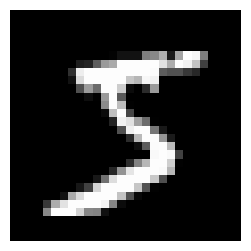

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(3, 3))   # 3x3 英寸
plt.imshow(img, cmap='gray')
plt.axis('off')   # 不显示坐标轴
plt.show()

### 神经网络的推理处理
下面，我们对这个 MNIST 数据集实现神经网络的推理处理。神经网络
的输入层有 784 个神经元，输出层有 10 个神经元。输入层的 784 这个数字来
源于图像大小的 28 × 28 = 784，输出层的 10 这个数字来源于 10 类别分类（数
字 0 到 9，共 10 类别）。此外，这个神经网络有 2 个隐藏层，第 1 个隐藏层有
50 个神经元，第 2 个隐藏层有 100 个神经元。这个 50 和 100 可以设置为任何值。
下面我们先定义 get_data()、init_network()、predict() 这 3 个函数（代码在
ch03/neuralnet_mnist.py 中）
。

In [32]:
import pickle

def get_data():
    (x_train, t_train), (x_test, t_test) = load_mnist(
        flatten=True, normalize=True, one_hot_label=False
    )
    return x_test, t_test

def init_network():
    with open("sample_weight.pkl", 'rb') as f:
        network = pickle.load(f)
    return network

def sigmoid(x):
    return 1 / (1 + np.exp(-x))
def softmax(x):
    x = x - np.max(x, axis=-1, keepdims=True)   # オーバーフロー対策
    return np.exp(x) / np.sum(np.exp(x), axis=-1, keepdims=True)

def predict(network, x):
    W1, W2, W3 = network['W1'], network['W2'], network['W3']
    b1, b2, b3 = network['b1'], network['b2'], network['b3']

    a1 = np.dot(x, W1) + b1
    z1 = sigmoid(a1)
    a2 = np.dot(z1, W2) + b2
    z2 = sigmoid(a2)
    a3 = np.dot(z2, W3) + b3
    y = softmax(a3)

    return y

In [28]:
x,t = get_data()
x, t

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 784), dtype=float32),
 array([7, 2, 1, ..., 4, 5, 6], shape=(10000,), dtype=uint8))

In [30]:
network = init_network()

In [33]:
accuracy_cnt = 0
for i in range(len(x)):
    y = predict(network, x[i])
    p = np.argmax(y)  # 获取最大值的索引
    if p == t[i]:
        accuracy_cnt += 1

print("Accuracy: " + str(accuracy_cnt / len(x)))

Accuracy: 0.9352


### 批处理

In [35]:
x,_=get_data()
network = init_network()
w1,w2,w3 = network['W1'], network['W2'], network['W3']
x.shape, w1.shape, w2.shape, w3.shape

((10000, 784), (784, 50), (50, 100), (100, 10))

In [37]:
x,t = get_data()
network = init_network()
batch_size = 100 
accuracy_cnt = 0

for i in range(0, len(x), batch_size):
    x_batch = x[i:i+batch_size]
    y_batch = predict(network, x_batch)
    p = np.argmax(y_batch, axis=1)
    accuracy_cnt += np.sum(p == t[i:i+batch_size])

print("Accuracy: " + str(float(accuracy_cnt) / len(x)))

Accuracy: 0.9352


In [39]:
x = np.array([[0.1,0.8,0.1],[0.3,0.1,0.6],[0.2, 0.5, 0.3], [0.8, 0.1, 0.1]])
y = np.argmax(x,axis=1)
y

array([1, 2, 1, 0])

In [40]:
y = np.array([1,2,1,0])
t = np.array([1,2,0,0])
y == t

array([ True,  True, False,  True])

In [41]:
np.sum(y==t)

np.int64(3)

# 小结
本章介绍了神经网络的前向传播。本章介绍的神经网络和上一章的感知
机在信号的按层传递这一点上是相同的，但是，向下一个神经元发送信号时，
改变信号的激活函数有很大差异。神经网络中使用的是平滑变化的 sigmoid
函数，而感知机中使用的是信号急剧变化的阶跃函数。这个差异对于神经网
络的学习非常重要，我们将在下一章介绍。

本章所学的内容
• 神经网络中的激活函数使用平滑变化的 sigmoid 函数或 ReLU 函数。
• 通过巧妙地使用 NumPy 多维数组，可以高效地实现神经网络。
• 机器学习的问题大体上可以分为回归问题和分类问题。
• 关于输出层的激活函数，回归问题中一般用恒等函数，分类问题中
一般用 softmax 函数。
• 分类问题中，输出层的神经元的数量设置为要分类的类别数。
• 输入数据的集合称为批。通过以批为单位进行推理处理，能够实现
高速的运算。